# Garimpo and the gold-laundering rules

Does garimpo respond to the rules on laundering gold where gold can only be mined
illegally? This is lead 1's main equation (`output/research/mining_economics_leads.md`,
lead 1):

- **Exposure (IGD):** never-exploited SGB gold occurrences inside protected areas that
  bar mining (Indigenous lands from the declaration onward, integral-protection units
  and extractive reserves) and were in force by 2012 (`protected_areas`, counted in
  `geology_adm2`; lands dated by FUNAI's first declaration, homologation or registry
  act, units by their creation year), in the municipality. Variants add the same
  deposits upstream (within 200 km, without limit, or in an Otto-4 sub-basin upstream),
  or count any gold occurrence in protected areas.
- **Shocks:** the 2013 good-faith presumption (Lei 12.844, July 2013) let gold of any
  origin be sold on a seller's declaration; the STF suspended it in April 2023.
  IGD × post-2013 and IGD × post-2023.
- **Outcomes:** the C11 garimpo share of the municipality's own trenches (gold and all
  substances, pp, 2004–2019, so no 2023 term); SIVEP garimpo malaria cases by infection
  municipality (all, local, incoming, any; 2004–2024); gold PLG requests and grants
  (`mining`). Non-garimpo malaria is the outcome placebo.
- **Specification:** municipality and year FE, the log BRL gold price × never-exploited
  deposits anywhere in the municipality as a control, unweighted, Legal Amazon, Otto-3
  clusters.
- **Inference:** Otto-3 SEs and the restricted wild-cluster bootstrap, which can
  over-reject with few treated units (E10). Randomization inference permutes IGD
  across municipalities and rebuilds every IGD term (999 draws); among municipalities with gold
  occurrences it is the binding test.
- **Checks:** state×year FE; the law dated from 2014; an IGD × post-2016 term for the
  enforcement collapse; an IGD-specific trend; without Roraima; garimpo enforcement
  counts (IBAMA fines, embargoes, seizures) as a control; municipalities with gold
  occurrences only; the exposure variants; and tin occurrences in protected areas × the
  same dates as a placebo.

Tables go to `output/analysis/garimpo/laundering/` (gitignored).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import garimpo_laundering as L

warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.float_format", lambda value: f"{value:.4g}")

OUT = PROJECT_ROOT / "output" / "analysis" / "garimpo" / "laundering"
OUT.mkdir(parents=True, exist_ok=True)
COLUMNS = ["term", "estimate", "se_basin", "p_basin", "p_wcb", "p_permutation", "n_obs", "n_exposed",
           "n_exposed_basins", "mean_y_exposed_pre"]

frame = L.build_frame()
frame.shape

(16212, 277)

## 1. Sample and exposure

In [2]:
sample = L.sample_table(frame)
sample.to_csv(OUT / "sample.csv", header=["value"])
display(sample.to_frame("value"))

municipalities = frame.drop_duplicates("mun_id")
by_state = municipalities.groupby("state")[[*L.EXPOSURES, L.TIN_IGD]].sum().astype(int)
igd_cases = frame[frame[L.IGD] > 0].groupby(["state", "year"])["inf_garimpo"].sum().unstack(fill_value=0)
display(by_state)
display(igd_cases.loc[:, [2008, 2012, 2013, 2016, 2019, 2022, 2023, 2024]])

igd = municipalities[municipalities[L.IGD] > 0]
listing = igd[["mun_id", "state", "gold_occurrences_unexploited_protected", "protected_2012_share", L.CLUSTER]]
cases = frame[frame[L.IGD] > 0].groupby("mun_id")["inf_garimpo"].sum().rename("garimpo cases 2004-2024")
display(listing.set_index("mun_id").join(cases).sort_values("garimpo cases 2004-2024", ascending=False))

,value
Legal Amazon municipalities in the panel,772
"exposed: never-exploited gold in protected areas, in the municipality",27
exposed: ... or within 200 km upstream,48
exposed: ... or anywhere upstream,136
exposed: ... or in an Otto-4 sub-basin upstream,79
"exposed: any gold occurrence in protected areas, in the municipality",45
exposed: tin in protected areas (placebo),23
Otto-3 basins with an IGD municipality,19
garimpo cases 2004-2024,2.481e+05
share in IGD municipalities,0.4204


,igd,igd_upstream_200,igd_upstream_all,igd_otto,igd_all_gold,tin_igd
state,,,,,,
11,1,1,11,10,6,7
12,0,0,0,0,1,0
13,3,6,35,18,5,4
14,6,6,10,10,9,3
15,9,19,59,26,14,9
16,6,10,15,13,6,0
17,0,0,0,0,0,0
21,0,0,0,0,1,0
51,2,6,6,2,3,0


year,2008,2012,2013,2016,2019,2022,2023,2024
state,,,,,,,,
11,658,4,0,0,166,84,56,37
13,81,2,5,24,35,95,72,87
14,3,9,20,46,2261,1.178e+04,5977,1288
15,1304,1168,744,1362,1137,3653,4285,4850
16,824,949,1190,762,502,1103,2056,2066
51,516,111,10,6,64,384,678,483


,state,gold_occurrences_unexploited_protected,protected_2012_share,otto_basin_l3,garimpo cases 2004-2024
mun_id,,,,,
150375,15,1,0.5716,443,3.34e+04
140005,14,2,0.7455,484,2.224e+04
160020,16,2,0.4291,397,1.222e+04
140030,14,1,0.5828,484,7697
150050,15,9,0.4998,432,4474
110009,11,1,0.3102,462,4065
510325,51,1,0.1633,462,3842
160015,16,1,0.6614,398,3279
160050,16,9,0.7067,396,2839


**Reading the results.** IGD is concentrated but thin.
- 27 of the 772 Legal Amazon municipalities hold never-exploited gold inside a protected
  area in force by 2012: Pará 9, Roraima 6, Amapá 6, Amazonas 3, Mato Grosso 2,
  Rondônia 1. They lie in 19 Otto-3 basins.
- Adding upstream deposits widens the group to 48 (within 200 km), 79 (Otto-4) or 136
  (anywhere upstream).
- The 27 hold 42% of the 248,000 garimpo cases of 2004–2024 but only 14% of the gold PLG
  requests. In Roraima the cases are the Yanomami rush: a few dozen a year before 2019,
  2,261 in 2019 and 11,780 in 2022.

## 2. Event study

Coefficients of IGD × year (2012 omitted), with the price × deposits control, municipality and
year FE and Otto-3 SEs, for the local exposure and the Otto-4 upstream variant; for the cases
also without Roraima.

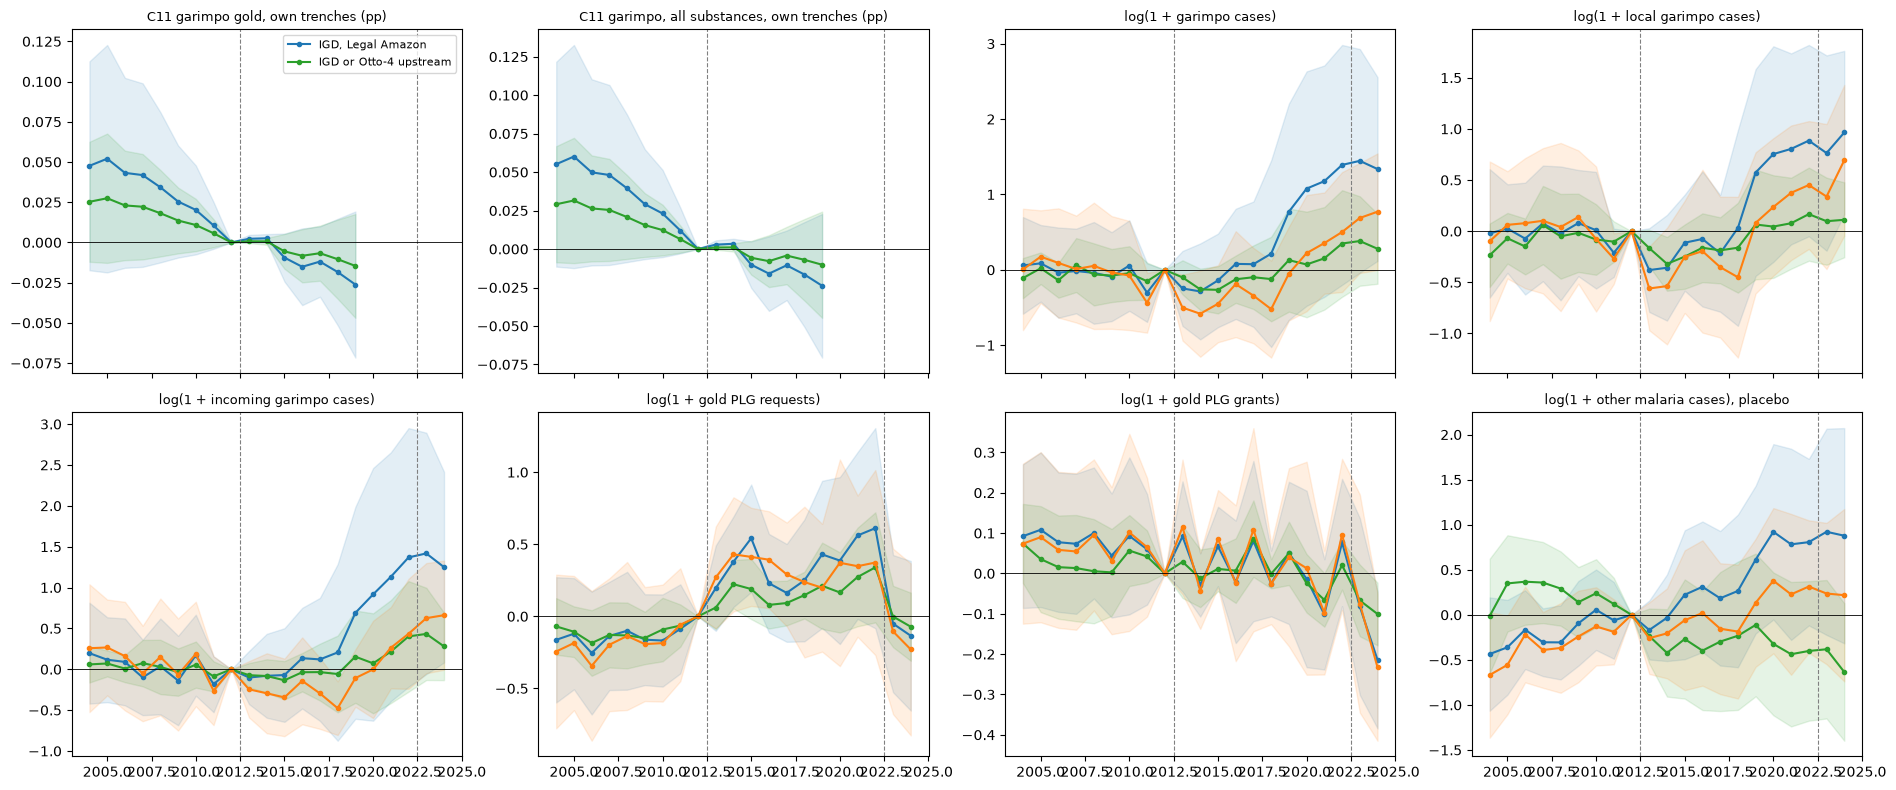

outcome,c11_garimpo_gold_pp,c11_garimpo_pp,log1p_garimpo_cases,log1p_garimpo_incoming,log1p_garimpo_local,log1p_other_malaria,log1p_plg_grants_gold,log1p_plg_requests_gold
year,,,,,,,,
2004,0.048,0.055,0.059,0.197,-0.022,-0.435,0.092,-0.163
2005,0.052,0.06,0.086,0.117,0.025,-0.36,0.108,-0.12
2006,0.043,0.05,-0.037,0.09,-0.072,-0.164,0.077,-0.254
2007,0.042,0.048,-0.015,-0.1,0.076,-0.304,0.073,-0.136
2008,0.034,0.039,-0.04,0.035,-0.022,-0.306,0.1,-0.1
2009,0.025,0.029,-0.09,-0.138,0.079,-0.094,0.044,-0.162
2010,0.02,0.023,0.057,0.172,0.009,0.056,0.093,-0.168
2011,0.011,0.012,-0.302,-0.183,-0.211,-0.061,0.06,-0.087
2012,0,0,0,0,0,0,0,0


In [3]:
ES_OUTCOMES = ["c11_garimpo_gold_pp", "c11_garimpo_pp", "log1p_garimpo_cases", "log1p_garimpo_local",
               "log1p_garimpo_incoming", "log1p_plg_requests_gold", "log1p_plg_grants_gold", "log1p_other_malaria"]
studies = pd.concat(
    [L.event_study(frame, outcome).assign(sample="IGD, Legal Amazon") for outcome in ES_OUTCOMES]
    + [L.event_study(frame, outcome, exposure="igd_otto").assign(sample="IGD or Otto-4 upstream")
       for outcome in ES_OUTCOMES]
    + [L.event_study(frame, outcome, drop_states=(L.RORAIMA,)).assign(sample="IGD, without Roraima")
       for outcome in ES_OUTCOMES[2:]],
    ignore_index=True,
)
studies.to_csv(OUT / "event_study.csv", index=False)

fig, axes = plt.subplots(2, 4, figsize=(19, 8), sharex=True)
colors = {"IGD, Legal Amazon": "C0", "IGD or Otto-4 upstream": "C2", "IGD, without Roraima": "C1"}
for ax, outcome in zip(axes.ravel(), ES_OUTCOMES):
    for sample_name, color in colors.items():
        part = studies[(studies.outcome == outcome) & (studies["sample"] == sample_name)]
        if part.empty:
            continue
        ax.plot(part.year, part.estimate, marker="o", ms=3, color=color, label=sample_name)
        ax.fill_between(part.year, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se,
                        color=color, alpha=0.12)
    for year in (L.LAW_YEAR, L.REVERSAL_YEAR):
        ax.axvline(year - 0.5, color="grey", lw=0.8, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(L.OUTCOMES[outcome][0], fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

wide = studies.pivot_table(index="year", columns=["sample", "outcome"], values="estimate")
display(wide["IGD, Legal Amazon"].round(3))

**Reading the results.** The activity measures do not follow the laundering dates; the
permit requests do.
- *C11 garimpo:* the IGD gap falls smoothly, from +0.05 pp in 2004 to −0.03 pp in 2019
  relative to 2012, with no step in 2013.
- *Garimpo cases:* below 2012 in 2013–15 (−0.25 to −0.29 log points), near zero through
  2018, then +0.77 in 2019, rising to +1.45 in 2023 and +1.34 in 2024. They do not fall
  after the 2023 suspension.
  - Non-garimpo malaria rises with them from 2019 (+0.61 to +0.92), so the break is not
    specific to garimpo.
  - Without Roraima, cases sit 0.2–0.6 below 2012 in 2013–18 and rise to +0.77 by 2024.
- *Gold PLG requests:* −0.1 to −0.25 in 2004–11, then +0.20 (2013), +0.54 (2015) and
  +0.61 (2022). They fall back to −0.05 in 2023 and −0.13 in 2024: up when the
  good-faith rule starts, down when it is suspended. Grants stay flat.
- With the Otto-4 upstream variant everything is weaker. Cases reach +0.35 by 2022, and
  requests +0.34.

## 3. IGD × post-2013 and × post-2023, and checks

Permutation p-values for the baseline, state×year FE, the spec without Roraima, and municipalities with gold occurrences only (permuting IGD among them).

In [4]:
table = L.run_table(frame)
table.to_csv(OUT / "laundering.csv", index=False)
for outcome in L.OUTCOMES:
    print(outcome)
    display(table[table.outcome == outcome].set_index(["spec", "exposure"])[[c for c in COLUMNS if c in table]])

c11_garimpo_gold_pp


term  estimate  se_basin  p_basin   p_wcb  p_permutation     n_obs  n_exposed  n_exposed_basins  mean_y_exposed_pre
spec                                  exposure                                                                                                                                 
baseline                              igd               post2013  -0.03552   0.02682   0.1876  0.1326          0.062 1.235e+04         27                19             0.01243
state x year FE                       igd               post2013  -0.03342    0.0236   0.1589 0.07371          0.066 1.235e+04         27                19             0.01243
law from 2014                         igd               post2013  -0.03421    0.0262   0.1937   0.143            NaN 1.235e+04         27                19             0.01243
+ IGD x post-2016                     igd               post2013  -0.02811    0.0204   0.1704  0.1313            NaN 1.235e+04         27                19             0.01243
                                      igd               post2016  -0.01425   0.01245   0.2545  0.3111            NaN 1.235e+04         27                19             0.01243
+ IGD trend                           igd               post2013  0.004551  0.002834   0.1106  0.1308            NaN 1.235e+04         27                19             0.01243
                                      igd                  trend  -0.00568  0.004174   0.1757  0.1592            NaN 1.235e+04         27                19             0.01243
without Roraima                       igd               post2013  -0.03654   0.02812   0.1959  0.1384          0.047 1.211e+04         21                17             0.01581
+ garimpo enforcement                 igd               post2013   -0.0356   0.02672   0.1849   0.127            NaN 1.235e+04         27                19             0.01243
gold municipalities only              igd               post2013  -0.04084   0.03081   0.1905  0.1152          0.072      2464         27                19             0.01243
exposure: + 200 km upstream           igd_upstream_200  post2013  -0.02146   0.02485   0.3892  0.6628            NaN 1.235e+04         48                25             0.04726
exposure: + all upstream              igd_upstream_all  post2013  -0.01388   0.01364   0.3104  0.4636            NaN 1.235e+04        136                61             0.01683
exposure: + Otto-4 upstream           igd_otto          post2013  -0.02012   0.01769   0.2573   0.214            NaN 1.235e+04         79                37             0.01664
exposure: any gold in protected areas igd_all_gold      post2013  -0.02025   0.02363   0.3931  0.6786            NaN 1.235e+04         45                25             0.04461
placebo: + tin in protected areas     igd               post2013   -0.0346   0.02495   0.1678  0.1047            NaN 1.235e+04         27                19             0.01243
                                      tin_igd           post2013  -0.00405   0.01074   0.7066     NaN            NaN       NaN        NaN               NaN                 NaN

c11_garimpo_pp


term  estimate  se_basin  p_basin   p_wcb  p_permutation     n_obs  n_exposed  n_exposed_basins  mean_y_exposed_pre
spec                                  exposure                                                                                                                                 
baseline                              igd               post2013  -0.03869    0.0272   0.1571   0.112           0.05 1.235e+04         27                19             0.02939
state x year FE                       igd               post2013  -0.03549   0.02419   0.1445 0.09131          0.055 1.235e+04         27                19             0.02939
law from 2014                         igd               post2013   -0.0368   0.02655   0.1678  0.1264            NaN 1.235e+04         27                19             0.02939
+ IGD x post-2016                     igd               post2013  -0.03193    0.0208    0.127 0.09221            NaN 1.235e+04         27                19             0.02939
                                      igd               post2016  -0.01302   0.01279   0.3104  0.4287            NaN 1.235e+04         27                19             0.02939
+ IGD trend                           igd               post2013  0.005246  0.002945  0.07696   0.105            NaN 1.235e+04         27                19             0.02939
                                      igd                  trend -0.006229  0.004241   0.1441   0.131            NaN 1.235e+04         27                19             0.02939
without Roraima                       igd               post2013  -0.03913    0.0285    0.172  0.1269          0.047 1.211e+04         21                17             0.03485
+ garimpo enforcement                 igd               post2013  -0.03882   0.02712   0.1545  0.1102            NaN 1.235e+04         27                19             0.02939
gold municipalities only              igd               post2013  -0.04466   0.03125   0.1587 0.09431           0.07      2464         27                19             0.02939
exposure: + 200 km upstream           igd_upstream_200  post2013  -0.01996   0.02554   0.4359  0.6855            NaN 1.235e+04         48                25             0.07107
exposure: + all upstream              igd_upstream_all  post2013  -0.01398   0.01377   0.3117  0.4602            NaN 1.235e+04        136                61             0.03142
exposure: + Otto-4 upstream           igd_otto          post2013  -0.02071   0.01779   0.2464  0.2034            NaN 1.235e+04         79                37              0.0305
exposure: any gold in protected areas igd_all_gold      post2013  -0.02116   0.02394   0.3783    0.61            NaN 1.235e+04         45                25             0.06076
placebo: + tin in protected areas     igd               post2013  -0.03806   0.02546   0.1371 0.09331            NaN 1.235e+04         27                19             0.02939
                                      tin_igd           post2013 -0.002796   0.01236   0.8214     NaN            NaN       NaN        NaN               NaN                 NaN

log1p_garimpo_cases


...

term  estimate  se_basin   p_basin   p_wcb  p_permutation     n_obs  n_exposed  n_exposed_basins  mean_y_exposed_pre
spec                                  exposure                                                                                                                                  
baseline                              igd               post2013    0.4949    0.3181     0.122  0.1718          0.058 1.621e+04         27                19                6.02
                                      igd               post2023    0.4515    0.3233    0.1648  0.2487          0.008 1.621e+04         27                19                6.02
state x year FE                       igd               post2013    0.4203    0.2617    0.1105  0.1309          0.038 1.621e+04         27                19                6.02
                                      igd               post2023    0.6253    0.2704   0.02219  0.0391          0.001 1.621e+04         27                19                6.02
law from 2014                         igd               post2013    0.5686    0.3257   0.08302  0.1407            NaN 1.621e+04         27                19                6.02
                                      igd               post2023    0.4026     0.312     0.199  0.2754            NaN 1.621e+04         27                19                6.02
+ IGD x post-2016                     igd               post2013    0.1629    0.2754    0.5551  0.5631            NaN 1.621e+04         27                19                6.02
                                      igd               post2023    0.3177    0.2797    0.2578  0.3225            NaN 1.621e+04         27                19                6.02
                                      igd               post2016    0.5171    0.2369   0.03071 0.05521            NaN 1.621e+04         27                19                6.02
+ IGD trend                           igd               post2013   -0.2693    0.2946    0.3622  0.3673            NaN 1.621e+04         27                19                6.02
                                      igd               post2023  -0.02507    0.2318     0.914  0.9176            NaN 1.621e+04         27                19                6.02
                                      igd                  trend   0.08834   0.03445   0.01138  0.0249            NaN 1.621e+04         27                19                6.02
without Roraima                       igd               post2013    0.2776    0.3518    0.4313  0.4375          0.337  1.59e+04         21                17                5.82
                                      igd               post2023    0.1711    0.3158    0.5888  0.6026          0.311  1.59e+04         21                17                5.82
+ garimpo enforcement                 igd               post2013    0.4587    0.3134    0.1455  0.1863            NaN 1.621e+04         27                19                6.02
                                      igd               post2023    0.2958    0.2645    0.2653   0.313            NaN 1.621e+04         27                19                6.02
gold municipalities only              igd               post2013    0.6461     0.338   0.06114 0.09501          0.039      3234         27                19                6.02
                                      igd               post2023    0.3493    0.3409    0.3101  0.3806          0.083      3234         27                19                6.02
exposure: + 200 km upstream           igd_upstream_200  post2013   -0.4398    0.3905    0.2619  0.2838            NaN 1.621e+04         48                25               5.674
                                      igd_upstream_200  post2023   0.07109    0.2629    0.7872  0.7956            NaN 1.621e+04         48                25               5.674
exposure: + all upstream              igd_upstream_all  post2013   -0.8724     0.222 0.0001324       0            NaN 1.621e+04        136                61          

log1p_plg_requests_gold


term  estimate  se_basin   p_basin     p_wcb  p_permutation     n_obs  n_exposed  n_exposed_basins  mean_y_exposed_pre
spec                                  exposure                                                                                                                                    
baseline                              igd               post2013    0.4847    0.1209 9.776e-05     0.001          0.001 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.4831    0.1162 5.568e-05    0.0021          0.001 1.621e+04         27                19              0.2113
state x year FE                       igd               post2013    0.4851    0.1331 0.0003739    0.0011          0.001 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.4928    0.1438 0.0008015    0.0023          0.001 1.621e+04         27                19              0.2113
law from 2014                         igd               post2013    0.4691    0.1211 0.0001622    0.0015            NaN 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.5036    0.1124 1.511e-05    0.0016            NaN 1.621e+04         27                19              0.2113
+ IGD x post-2016                     igd               post2013    0.4909    0.1225 9.872e-05    0.0032            NaN 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.4806    0.1036  7.92e-06    0.0011            NaN 1.621e+04         27                19              0.2113
                                      igd               post2016 -0.009678    0.1241    0.9379    0.9381            NaN 1.621e+04         27                19              0.2113
+ IGD trend                           igd               post2013    0.2867    0.1458   0.05122   0.07711            NaN 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.6066    0.1274 4.709e-06 0.0006001            NaN 1.621e+04         27                19              0.2113
                                      igd                  trend   0.02289   0.02248    0.3102    0.3797            NaN 1.621e+04         27                19              0.2113
without Roraima                       igd               post2013    0.4957    0.1399 0.0005366    0.0013          0.001  1.59e+04         21                17              0.2631
                                      igd               post2023   -0.5052    0.1401 0.0004293    0.0026          0.001  1.59e+04         21                17              0.2631
+ garimpo enforcement                 igd               post2013    0.4672    0.1123 5.457e-05     0.001            NaN 1.621e+04         27                19              0.2113
                                      igd               post2023   -0.5587    0.1206 8.081e-06    0.0011            NaN 1.621e+04         27                19              0.2113
gold municipalities only              igd               post2013    0.3525    0.1401   0.01481    0.0276          0.002      3234         27                19              0.2113
                                      igd               post2023   -0.2017    0.1324    0.1333    0.1404          0.139      3234         27                19              0.2113
exposure: + 200 km upstream           igd_upstream_200  post2013    0.5229    0.1074 2.934e-06         0            NaN 1.621e+04         48                25              0.2425
                                      igd_upstream_200  post2023   -0.3555   0.09548 0.0002825    0.0029            NaN 1.621e+04         48                25              0.2425
exposure: + all upstream              igd_upstream_all  post2013    0.1978   0.05044 0.0001363    0.0003            NaN 1.

log1p_plg_grants_gold


term  estimate  se_basin  p_basin     p_wcb  p_permutation     n_obs  n_exposed  n_exposed_basins  mean_y_exposed_pre
spec                                  exposure                                                                                                                                   
baseline                              igd               post2013  -0.04647   0.06404   0.4692    0.4933          0.064 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1601   0.07539   0.0354    0.0274          0.001 1.621e+04         27                19             0.03875
state x year FE                       igd               post2013  -0.04009   0.06219   0.5202      0.54          0.086 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1616   0.08374  0.05565    0.0412          0.001 1.621e+04         27                19             0.03875
law from 2014                         igd               post2013  -0.05891    0.0618   0.3421    0.3715            NaN 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1538   0.07489  0.04179    0.0311            NaN 1.621e+04         27                19             0.03875
+ IGD x post-2016                     igd               post2013  -0.02525   0.05158   0.6251    0.6402            NaN 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1516   0.07543  0.04636    0.0283            NaN 1.621e+04         27                19             0.03875
                                      igd               post2016  -0.03306   0.04629   0.4764    0.4941            NaN 1.621e+04         27                19             0.03875
+ IGD trend                           igd               post2013   0.01476   0.04064    0.717    0.7283            NaN 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1219   0.09519   0.2022     0.212            NaN 1.621e+04         27                19             0.03875
                                      igd                  trend -0.007079   0.01039   0.4966    0.5145            NaN 1.621e+04         27                19             0.03875
without Roraima                       igd               post2013  -0.03129   0.06999   0.6555    0.6723          0.167  1.59e+04         21                17             0.04982
                                      igd               post2023   -0.1768   0.09071  0.05331    0.0416          0.001  1.59e+04         21                17             0.04982
+ garimpo enforcement                 igd               post2013  -0.04942   0.06442   0.4443    0.4738            NaN 1.621e+04         27                19             0.03875
                                      igd               post2023   -0.1728   0.08208  0.03703    0.0334            NaN 1.621e+04         27                19             0.03875
gold municipalities only              igd               post2013  -0.05176   0.06636   0.4388    0.4545          0.328      3234         27                19             0.03875
                                      igd               post2023   -0.1306   0.07855   0.1021   0.09081          0.059      3234         27                19             0.03875
exposure: + 200 km upstream           igd_upstream_200  post2013  0.006694   0.04088   0.8702    0.8898            NaN 1.621e+04         48                25             0.07401
                                      igd_upstream_200  post2023  -0.09481   0.05177  0.06912   0.06471            NaN 1.621e+04         48                25             0.07401
exposure: + all upstream              igd_upstream_all  post2013  -0.01236   0.01783   0.4891    0.6424            NaN 1.621e+04        136     

In [5]:
main = table[table.exposure.isin(L.EXPOSURES)]
for term in ("post2013", "post2023"):
    part = main[main.term == term]
    print(term, "estimates")
    display(part.pivot_table(index="spec", columns="outcome", values="estimate", sort=False).round(3))
    print(term, "Otto-3 p-values")
    display(part.pivot_table(index="spec", columns="outcome", values="p_basin", sort=False).round(3))
    print(term, "permutation p-values")
    display(part.dropna(subset=["p_permutation"]).pivot_table(index="spec", columns="outcome",
                                                              values="p_permutation", sort=False).round(3))

post2013 estimates


outcome,c11_garimpo_gold_pp,c11_garimpo_pp,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria,log1p_plg_requests_gold,log1p_plg_grants_gold
spec,,,,,,,,,
baseline,-0.036,-0.039,0.343,0.122,0.328,0.12,0.495,0.485,-0.046
state x year FE,-0.033,-0.035,0.076,-0.03,0.039,0.062,0.42,0.485,-0.04
law from 2014,-0.034,-0.037,0.459,0.244,0.415,0.106,0.569,0.469,-0.059
+ IGD x post-2016,-0.028,-0.032,-0.221,-0.295,-0.129,0.095,0.163,0.491,-0.025
+ IGD trend,0.005,0.005,-0.572,-0.634,-0.421,0.078,-0.269,0.287,0.015
without Roraima,-0.037,-0.039,-0.175,-0.165,-0.214,0.038,0.278,0.496,-0.031
+ garimpo enforcement,-0.036,-0.039,0.287,0.082,0.276,0.114,0.459,0.467,-0.049
gold municipalities only,-0.041,-0.045,0.473,0.211,0.427,0.163,0.646,0.352,-0.052
exposure: + 200 km upstream,-0.021,-0.02,0,-0.09,0.047,-0.009,-0.44,0.523,0.007


post2013 Otto-3 p-values


outcome,c11_garimpo_gold_pp,c11_garimpo_pp,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria,log1p_plg_requests_gold,log1p_plg_grants_gold
spec,,,,,,,,,
baseline,0.188,0.157,0.51,0.749,0.518,0.161,0.122,0,0.469
state x year FE,0.159,0.145,0.854,0.934,0.918,0.356,0.11,0,0.52
law from 2014,0.194,0.168,0.375,0.507,0.425,0.169,0.083,0,0.342
+ IGD x post-2016,0.17,0.127,0.588,0.382,0.729,0.288,0.555,0,0.625
+ IGD trend,0.111,0.077,0.127,0.049,0.212,0.418,0.362,0.051,0.717
without Roraima,0.196,0.172,0.65,0.664,0.51,0.587,0.431,0.001,0.656
+ garimpo enforcement,0.185,0.154,0.561,0.826,0.561,0.173,0.146,0,0.444
gold municipalities only,0.191,0.159,0.373,0.582,0.414,0.064,0.061,0.015,0.439
exposure: + 200 km upstream,0.389,0.436,1,0.735,0.884,0.905,0.262,0,0.87


post2013 permutation p-values


...

outcome,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria,log1p_plg_requests_gold,log1p_plg_grants_gold
spec,,,,,,,
baseline,0.91,0.615,0.843,0.029,0.451,-0.483,-0.16
state x year FE,0.931,0.685,0.791,0.055,0.625,-0.493,-0.162
law from 2014,0.856,0.57,0.798,0.027,0.403,-0.504,-0.154
+ IGD x post-2016,0.682,0.446,0.659,0.018,0.318,-0.481,-0.152
+ IGD trend,0.339,0.143,0.376,0.002,-0.025,-0.607,-0.122
without Roraima,0.855,0.602,0.749,0.07,0.171,-0.505,-0.177
+ garimpo enforcement,0.668,0.44,0.621,0.002,0.296,-0.559,-0.173
gold municipalities only,0.852,0.621,0.791,-0.013,0.349,-0.202,-0.131
exposure: + 200 km upstream,0.577,0.289,0.531,0.053,0.071,-0.356,-0.095


post2023 Otto-3 p-values


outcome,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria,log1p_plg_requests_gold,log1p_plg_grants_gold
spec,,,,,,,
baseline,0,0,0.001,0.566,0.165,0,0.035
state x year FE,0.001,0.001,0.002,0.266,0.022,0.001,0.056
law from 2014,0,0.001,0,0.578,0.199,0,0.042
+ IGD x post-2016,0,0.005,0.001,0.674,0.258,0,0.046
+ IGD trend,0.151,0.416,0.151,0.961,0.914,0,0.202
without Roraima,0.001,0.004,0.003,0.137,0.589,0,0.053
+ garimpo enforcement,0.001,0.022,0.001,0.963,0.265,0,0.037
gold municipalities only,0.001,0.001,0.003,0.785,0.31,0.133,0.102
exposure: + 200 km upstream,0.001,0.031,0.004,0.249,0.787,0,0.069


post2023 permutation p-values


outcome,log1p_garimpo_cases,log1p_garimpo_local,log1p_garimpo_incoming,any_garimpo_case,log1p_other_malaria,log1p_plg_requests_gold,log1p_plg_grants_gold
spec,,,,,,,
baseline,0.001,0.001,0.001,0.378,0.008,0.001,0.001
state x year FE,0.001,0.001,0.001,0.114,0.001,0.001,0.001
without Roraima,0.001,0.001,0.001,0.078,0.311,0.001,0.001
gold municipalities only,0.001,0.001,0.001,0.785,0.083,0.139,0.059


**Reading the results.** Only the permit requests respond to the laundering rules
as lead 1 predicts.
- *C11 garimpo:* IGD × post-2013 is −0.036 pp (Otto-3 p 0.19) and +0.005 with an IGD
  trend. There is no rise after the 2013 rule.
- *Garimpo cases:*
  - IGD × post-2013 is +0.34 (Otto-3 p 0.51, wild-cluster bootstrap 0.63). It changes
    sign with an IGD trend (−0.57), without Roraima (−0.18) or with an IGD × post-2016
    term (−0.22).
  - IGD × post-2023 is +0.91 (p < 0.01): cases in 2023–24 are higher than in 2013–22,
    the wrong sign for a closed laundering route. It falls to +0.34 (p 0.15) with an
    IGD trend.
  - The IGD × post-2016 term itself is +0.88 (p 0.03), and non-garimpo malaria also
    moves (+0.52, p 0.03). The case series measures the 2019 break, not the rules.
- *Gold PLG requests:*
  - IGD × post-2013 is +0.49 log points. Otto-3 p < 0.01, wild-cluster bootstrap 0.001,
    permutation 0.001.
  - It holds with the law dated from 2014 (+0.47), with the post-2016 term (+0.49),
    without Roraima (+0.50), with the enforcement control (+0.47) and with state×year
    FE (+0.49).
  - Within gold municipalities it is +0.35, with permutation p 0.002 among them.
  - It shrinks to +0.29 (p 0.05) with an IGD trend.
  - IGD × post-2023 is −0.48 (p < 0.01). Within gold municipalities it is −0.20
    (Otto-3 p 0.13, permutation 0.14).
  - Gold PLG grants fall after 2023 (−0.16, p 0.04) and do not move after 2013.
- *Placebos:*
  - Tin in protected areas × post-2013 also raises gold PLG requests (+0.41, p 0.01),
    while the IGD term stays at +0.39. Part of the request rise is common to
    mineral-rich protected regions.
  - The permutation across all Legal Amazon municipalities rejects for non-garimpo
    malaria too in the baseline and state×year specs (p 0.001–0.06), and within gold
    municipalities for its post-2013 term (0.04). IGD municipalities are not exchangeable with others for the malaria
    outcomes. The permutation p-values are informative only for the permit outcomes,
    where the outcome placebo does not apply.
- **Bottom line.** The 2013 rule and its 2023 suspension show up in the paper trail:
  requests for garimpo permits rise in municipalities with gold inside protected areas
  after 2013 and fall after 2023. They do not show up in measured garimpo activity,
  which follows a smooth trend (C11) and the 2019 break (SIVEP).

## 4. Timing of the permit requests

Gold PLG requests by protocol quarter (`mining`'s monthly requests), 2009–2025, Legal
Amazon municipalities, zeros filled. The law dates from July 2013 (2013Q3) and the STF
suspension from April 2023 (2023Q2).

- **Counts:** gold requests in the Legal Amazon and in IGD municipalities, and IGD's share.
- **Event study:** IGD × quarter (2013Q2 omitted), municipality and quarter FE, Otto-3 SEs;
  all Legal Amazon municipalities and gold municipalities only.
- **Break scan:** IGD × post-q for every candidate quarter q from 2010Q1 to 2022Q4, on
  the quarters before 2023Q2. The least-squares break date is the q with the smallest
  residual sum of squares.

In [6]:
quarterly = L.quarterly_requests(frame)
exposed = quarterly[L.IGD] > 0
gold = (quarterly[L.DEPOSITS] > 0) & ~exposed
counts = pd.DataFrame({
    "Legal Amazon": quarterly.groupby("quarter")["plg_requests_gold"].sum(),
    "IGD": quarterly[exposed].groupby("quarter")["plg_requests_gold"].sum(),
    "other deposit municipalities": quarterly[gold].groupby("quarter")["plg_requests_gold"].sum(),
})
counts["IGD share"] = counts["IGD"] / counts["Legal Amazon"]
counts.to_csv(OUT / "requests_quarterly.csv")
yearly = counts.drop(columns="IGD share").groupby(counts.index.year).sum()
yearly["IGD share"] = yearly["IGD"] / yearly["Legal Amazon"]
display(yearly.round(3))
display(counts.loc["2012Q1":"2015Q4"].round(3).T)
display(counts.loc["2022Q1":"2024Q4"].round(3).T)
by_municipality = (quarterly[exposed].assign(year=lambda f: f["quarter"].dt.year)
                   .pivot_table(index="year", columns="mun_id", values="plg_requests_gold", aggfunc="sum"))
top = by_municipality.sum().sort_values(ascending=False).index[:6]
display(by_municipality[top].loc[2009:])

,Legal Amazon,IGD,other deposit municipalities,IGD share
quarter,,,,
2009,205,23,64,0.112
2010,379,39,128,0.103
2011,519,60,282,0.116
2012,779,69,373,0.089
2013,1706,140,911,0.082
2014,894,111,331,0.124
2015,950,203,297,0.214
2016,1090,128,540,0.117
2017,924,129,428,0.14


quarter,2012Q1,2012Q2,2012Q3,2012Q4,2013Q1,2013Q2,2013Q3,2013Q4,2014Q1,2014Q2,2014Q3,2014Q4,2015Q1,2015Q2,2015Q3,2015Q4
Legal Amazon,93,155,140,391,321,659,500,226,300,189,180,225,184,159,118,489
IGD,5,6,22,36,44,46,13,37,20,26,24,41,28,100,33,42
other deposit municipalities,41,95,82,155,155,406,229,121,81,50,94,106,63,23,52,159
IGD share,0.054,0.039,0.157,0.092,0.137,0.07,0.026,0.164,0.067,0.138,0.133,0.182,0.152,0.629,0.28,0.086


quarter,2022Q1,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
Legal Amazon,252,227,150,134,93,150,382,194,122,77,136,149
IGD,66,48,52,40,26,31,46,16,13,11,38,14
other deposit municipalities,75,84,38,61,25,39,172,59,61,23,52,29
IGD share,0.262,0.211,0.347,0.299,0.28,0.207,0.12,0.082,0.107,0.143,0.279,0.094


mun_id,150375,150060,150730,140002,510325,140020
year,,,,,,
2009,19,1,0,0,0,0
2010,31,5,0,0,0,0
2011,9,32,13,0,0,0
2012,30,12,5,4,0,0
2013,33,57,9,3,1,0
2014,32,15,7,17,0,0
2015,42,4,20,54,0,2
2016,43,22,11,0,3,1
2017,49,13,15,0,6,1


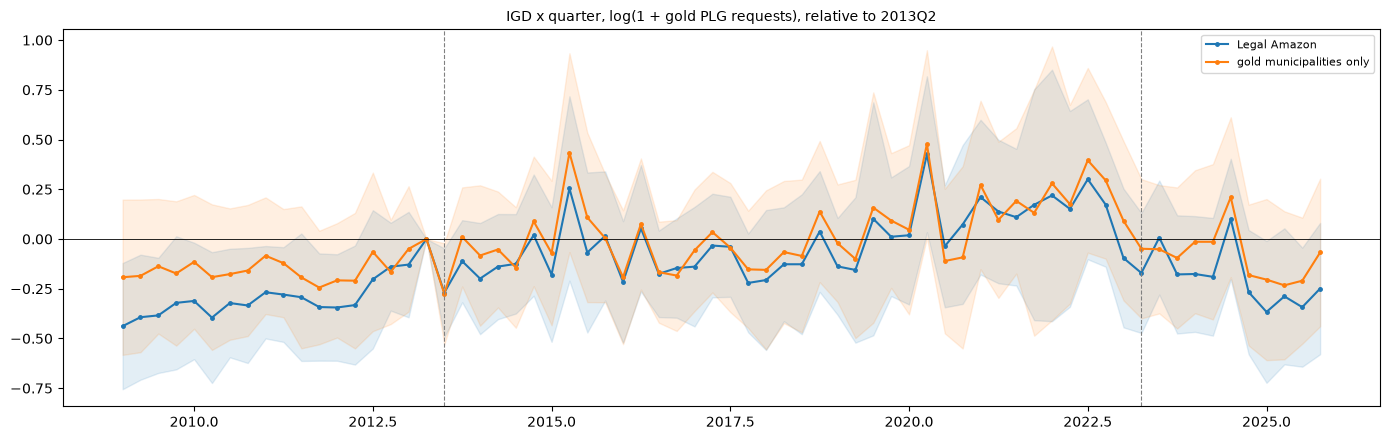

sample,Legal Amazon,gold municipalities only
year,,
2009,-0.384,-0.172
2010,-0.341,-0.16
2011,-0.296,-0.161
2012,-0.255,-0.162
2013,-0.128,-0.079
2014,-0.111,-0.048
2015,0.006,0.119
2016,-0.121,-0.117
2017,-0.108,-0.055


estimate                                    se                         
sample  Legal Amazon gold municipalities only Legal Amazon gold municipalities only
quarter                                                                            
2012Q1        -0.344                   -0.208        0.137                    0.147
2012Q2        -0.332                    -0.21        0.153                    0.174
2012Q3        -0.203                   -0.065        0.177                    0.203
2012Q4        -0.139                   -0.166        0.113                    0.134
2013Q1        -0.129                    -0.05        0.135                    0.161
2013Q2             0                        0            0                        0
2013Q3         -0.27                   -0.276        0.114                     0.13
2013Q4        -0.112                     0.01        0.105                    0.127
2014Q1        -0.199                   -0.083        0.143                     0.18
2014Q2        -0.139                   -0.053        0.135                    0.149
2014Q3        -0.125                   -0.143        0.128                    0.155
2014Q4         0.019                    0.088        0.156                    0.166

In [7]:
q_studies = pd.concat([
    L.quarterly_event_study(quarterly).assign(sample="Legal Amazon"),
    L.quarterly_event_study(quarterly, deposit_only=True).assign(sample="gold municipalities only"),
], ignore_index=True)
q_studies.to_csv(OUT / "event_study_quarterly.csv", index=False)
fig, ax = plt.subplots(figsize=(14, 4.5))
for (sample_name, part), color in zip(q_studies.groupby("sample", sort=False), ("C0", "C1")):
    x = part["quarter"].dt.year + (part["quarter"].dt.quarter - 1) / 4
    ax.plot(x, part.estimate, marker="o", ms=2.5, color=color, label=sample_name)
    ax.fill_between(x, part.estimate - 1.96 * part.se, part.estimate + 1.96 * part.se, color=color, alpha=0.12)
for quarter in (L.LAW_QUARTER, L.REVERSAL_QUARTER):
    period = pd.Period(quarter, freq="Q")
    ax.axvline(period.year + (period.quarter - 1) / 4, color="grey", lw=0.8, ls="--")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("IGD x quarter, log(1 + gold PLG requests), relative to 2013Q2", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
annual = (q_studies.assign(year=lambda f: f["quarter"].dt.year)
          .pivot_table(index="year", columns="sample", values="estimate", aggfunc="mean", sort=False))
display(annual.round(3))
display(q_studies[q_studies["quarter"].between(pd.Period("2012Q1", freq="Q"), pd.Period("2014Q4", freq="Q"))]
        .pivot_table(index="quarter", columns="sample", values=["estimate", "se"], sort=False).round(3))

Legal Amazon least-squares break: 2019Q3


,estimate,se,t,ssr,exposure,sample
break,,,,,,
2019Q3,0.3139,0.0989,3.175,2921,igd,Legal Amazon
2012Q4,0.3134,0.0499,6.275,2922,igd,Legal Amazon
2012Q3,0.3182,0.0516,6.17,2922,igd,Legal Amazon
2013Q1,0.3044,0.0476,6.388,2922,igd,Legal Amazon
2013Q2,0.296,0.0484,6.119,2923,igd,Legal Amazon
2014Q3,0.2778,0.0567,4.895,2923,igd,Legal Amazon


,estimate,se,t,ssr,exposure,sample
break,,,,,,
2012Q3,0.3182,0.0516,6.17,2922,igd,Legal Amazon
2012Q4,0.3134,0.0499,6.275,2922,igd,Legal Amazon
2013Q1,0.3044,0.0476,6.388,2922,igd,Legal Amazon
2013Q2,0.296,0.0484,6.119,2923,igd,Legal Amazon
2013Q3,0.2787,0.0476,5.857,2925,igd,Legal Amazon
2013Q4,0.2844,0.0505,5.628,2923,igd,Legal Amazon
2014Q1,0.2784,0.051,5.461,2924,igd,Legal Amazon
2014Q2,0.28,0.0532,5.261,2923,igd,Legal Amazon


gold municipalities only least-squares break: 2019Q3


,estimate,se,t,ssr,exposure,sample
break,,,,,,
2019Q3,0.2529,0.1065,2.374,2178,igd,gold municipalities only
2018Q4,0.2331,0.0947,2.463,2179,igd,gold municipalities only
2019Q4,0.2479,0.0992,2.5,2179,igd,gold municipalities only
2019Q2,0.2359,0.1061,2.223,2180,igd,gold municipalities only
2020Q2,0.2575,0.1065,2.417,2180,igd,gold municipalities only
2020Q1,0.2497,0.1042,2.395,2180,igd,gold municipalities only


,estimate,se,t,ssr,exposure,sample
break,,,,,,
2012Q3,0.2001,0.0617,3.244,2184,igd,gold municipalities only
2012Q4,0.1953,0.0604,3.235,2184,igd,gold municipalities only
2013Q1,0.2002,0.057,3.51,2184,igd,gold municipalities only
2013Q2,0.1957,0.058,3.376,2184,igd,gold municipalities only
2013Q3,0.1879,0.057,3.299,2184,igd,gold municipalities only
2013Q4,0.2029,0.0596,3.402,2182,igd,gold municipalities only
2014Q1,0.1957,0.0602,3.248,2183,igd,gold municipalities only
2014Q2,0.1963,0.062,3.167,2182,igd,gold municipalities only


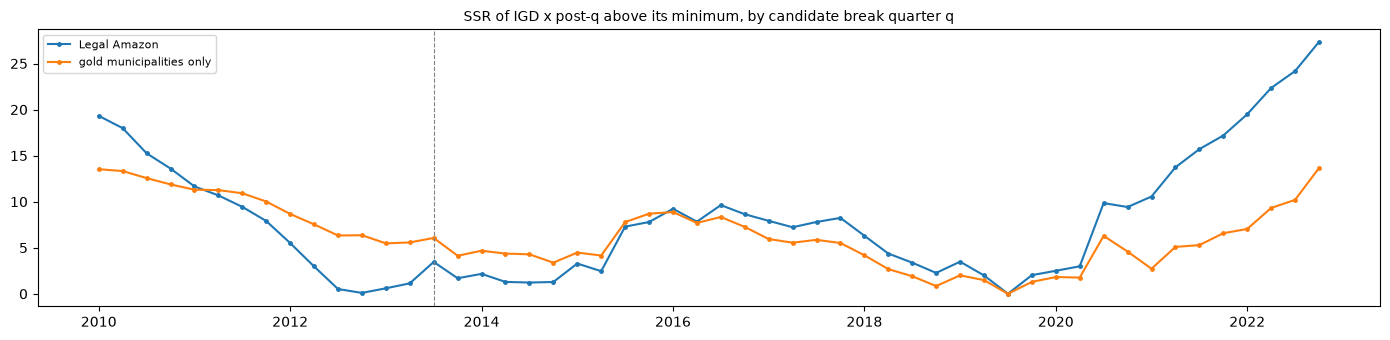

In [8]:
scans = pd.concat([
    L.break_scan(quarterly).assign(sample="Legal Amazon"),
    L.break_scan(quarterly, deposit_only=True).assign(sample="gold municipalities only"),
], ignore_index=True)
scans.to_csv(OUT / "break_scan.csv", index=False)
for sample_name, part in scans.groupby("sample", sort=False):
    part = part.set_index("break")
    print(sample_name, "least-squares break:", part["ssr"].idxmin())
    display(part.sort_values("ssr").head(6).round(4))
    display(part.loc[pd.Period("2012Q3", freq="Q"):pd.Period("2014Q2", freq="Q")].round(4))
fig, ax = plt.subplots(figsize=(14, 3.5))
for (sample_name, part), color in zip(scans.groupby("sample", sort=False), ("C0", "C1")):
    x = part["break"].dt.year + (part["break"].dt.quarter - 1) / 4
    ax.plot(x, part["ssr"] - part["ssr"].min(), marker="o", ms=2.5, color=color, label=sample_name)
period = pd.Period(L.LAW_QUARTER, freq="Q")
ax.axvline(period.year + (period.quarter - 1) / 4, color="grey", lw=0.8, ls="--")
ax.set_title("SSR of IGD x post-q above its minimum, by candidate break quarter q", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Reading the results.** The permit requests do not move in the quarter of the law. The
annual IGD × post-2013 term picks up a slow rise and the 2020–22 surge.
- *Counts:* Legal Amazon gold requests double in 2013 (779 to 1,706), but the surge runs
  from 2012Q4 to 2013Q3 and sits in the other deposit municipalities (406 in 2013Q2,
  before the law).
  - IGD's share of Legal Amazon requests is 8–12% in 2009–14 and lowest in 2013Q3
    (2.6%), the quarter of the law.
  - The share is 19–27% in 2018–22 and 8–16% in 2023–25.
- *Event study* (relative to 2013Q2):
  - The IGD gap rises steadily before the law, from −0.38 (2009 average) to −0.13 (2013).
  - It dips in 2013Q3 (−0.27, SE 0.11) and stays near −0.11 in 2014–18, apart from a
    2015 burst.
  - It turns positive from 2019Q3 and reaches +0.12 to +0.21 in 2020–22.
  - It falls to −0.11 in 2023 and −0.31 in 2025. In the Legal Amazon sample the fall starts
    in 2023Q1 (−0.10, from +0.17 in 2022Q4), before the April suspension; among gold
    municipalities it starts in 2023Q2. Quarterly SEs are 0.15–0.20.
- *Break scan:* the fit barely depends on the break date (the SSR ranges over 27 of
  2,921). The least-squares break is 2019Q3 in both samples. Among gold municipalities
  the quarters around the law fit worse than 2019Q3 (SSR 2,184 against 2,178).
- *Who files:* IGD requests come in batches from a few municipalities: Jacareacanga
  (150375; 134 in 2020), Altamira (150060; 57 in 2013), Amajari in Roraima (140002; 54 in
  2015) and São Félix do Xingu (150730).
